In [2]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch

In [3]:
datafr = pd.read_csv('ScorePolarFig1.csv')
datafr

,Mock CS-,Mock CS+,SFC CS-,SFC CS+
0,0.000000,0.121795,0.009047,-0.520693
1,0.014245,0.067416,0.265979,-0.298701
2,-0.137500,-0.040892,0.631336,-0.510595
3,-0.128713,0.000000,0.079344,-0.959412
4,-0.145833,0.154639,-0.275362,-0.185396
5,0.000000,0.173145,-0.195279,-0.514630
6,-0.011905,-0.117825,0.513075,-0.583452
7,0.183099,0.231293,-0.477064,-0.791411
8,0.028986,0.075075,-0.131429,-0.721587
9,0.109489,0.010909,0.924675,-0.404834


/var/folders/b7/k9l5l5ss13d27wd57vb8fq4w0000gn/T/ipykernel_32315/2430276105.py:16: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  ax = sns.stripplot(
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


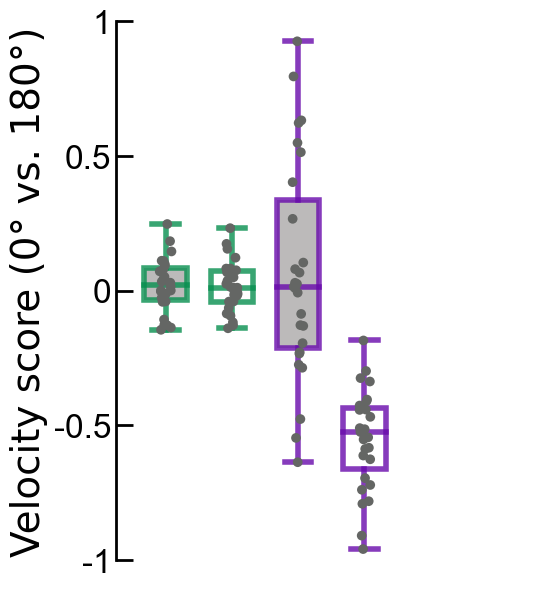

In [7]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}


text_boxplot = ['','***','****']

colors_fil = ["#aba9a9","#aba9a9","#aba9a9","#aba9a9","#aba9a9","#aba9a9"]
colors = ["#646664","#646664","#646664","#646664","#646664","#646664"]

colors_boxplot = ['#078f4f', "#078f4f",'#680aab', "#680aab",'#e66007', "#e66007"]

ax = sns.stripplot(
    data=datafr,
    size=7,
    palette=colors,
    jitter=0.09
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=datafr,
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_linewidth(2)


#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches

for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[i]  
    patch.set_edgecolor(col)
    patch.set_facecolor('None')    
    if (i%2==0):
        patch.set_facecolor(colors_fil[1])
        
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        

        
#END CHANGE BOXPLOT STYLE

plt.legend([],[], frameon=False)

ax.set_xticks([])
ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Velocity score (0° vs. 180°)', fontsize = 28)

ax.set_ylim([-1,1])
ax.set_xlim([-0.75,5.5])

ax.set_yticks([-1,-0.5,0,0.5,1], fontname='Arial')
ax.set_yticklabels(['-1','-0.5','0','0.5','1'],fontname='Arial')

# ax.set_xlim([-0.45,3.5])

#significance(ax,2.5,1,datafr['Mock CS-'].max(),text=text_boxplot[2])
significance(ax,6.5,1,datafr['SFC CS+'].max()-2,text=text_boxplot[0])

ax.tick_params(axis='y', which='major', direction='in',length=12, labelsize=24, width=2)


fig = ax.get_figure()

adjust_box_widths(fig, 0.8)
fig.set_size_inches(5.5,6)

plt.tight_layout()
fig.tight_layout()
fig.savefig("Fig1_PolarScores.jpg",dpi=600,bbox_inches='tight')
plt.savefig('Fig1_PolarScores.eps', dpi=600, format='eps')